# Laboratorium 3 — Dane obrazowe i wideo: potok i własny zbiór

**Cel:** zbudować potok danych od plików do tensorów. Wczytamy własny mini-zbiór przez `ImageFolder`, podejrzymy augmentację, a następnie potraktujemy **wideo jako sekwencję klatek** i przepuścimy klatki przez ten sam potok co obrazy.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## Budowa własnych zbiorów (dwie klasy)
Do pracy wykorzystano materiały własne. Edytowano oraz połączono fragmenty różnych ujęć samolotów oraz helikoptera w 4 filmiki.


In [2]:
import os
import urllib.request
import cv2
from PIL import Image
import torch
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

ROOT = "moje_dane"

videos = {
    "train": {
        "samolot": "https://raw.githubusercontent.com/wik990s/Rozpoznawanie_Obiekt-w_WS/refs/heads/main/pliki_rozpoznawanie_obiektow/samolot.mp4",
        "helikopter": "https://raw.githubusercontent.com/wik990s/Rozpoznawanie_Obiekt-w_WS/refs/heads/main/pliki_rozpoznawanie_obiektow/helikopter.mp4"
    },
    "val": {
        "samolot": "https://raw.githubusercontent.com/wik990s/Rozpoznawanie_Obiekt-w_WS/refs/heads/main/pliki_rozpoznawanie_obiektow/samolot_v.mp4",
        "helikopter": "https://raw.githubusercontent.com/wik990s/Rozpoznawanie_Obiekt-w_WS/refs/heads/main/pliki_rozpoznawanie_obiektow/helikopter_v.mp4"
    }
}

def extract_frames(video_url, split, class_name, every=10):
    if not video_url.startswith("http"):
        return

    output = os.path.join(ROOT, split, class_name)
    os.makedirs(output, exist_ok=True)
    temp_path = f"temp_{split}_{class_name}.mp4"

    urllib.request.urlretrieve(video_url, temp_path)
    cap = cv2.VideoCapture(temp_path)
    if not cap.isOpened():
        print(f"Błąd otwarcia pliku dla {class_name}")
        return

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames_meta = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"Wideo '{class_name}' ({split}): {fps:.2f} FPS, {total_frames_meta}")

    frame_idx, saved_count = 0, 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % every == 0:
            rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            img = Image.fromarray(rgb_frame)
            img.save(os.path.join(output, f"frame_{saved_count:04d}.jpg"))
            saved_count += 1

        frame_idx += 1

    cap.release()
    if os.path.exists(temp_path):
        os.remove(temp_path)

    print(f"Zapisano {saved_count} klatek dla folderu {split}/{class_name}.")

for split_name in videos:
    for cls_name, url in videos[split_name].items():
        extract_frames(url, split_name, cls_name, every=14)

Wideo 'samolot' (train): 29.71 FPS, 478
Zapisano 35 klatek dla folderu train/samolot.
Wideo 'helikopter' (train): 29.85 FPS, 541
Zapisano 39 klatek dla folderu train/helikopter.
Wideo 'samolot' (val): 29.79 FPS, 232
Zapisano 17 klatek dla folderu val/samolot.
Wideo 'helikopter' (val): 29.88 FPS, 165
Zapisano 12 klatek dla folderu val/helikopter.


Statystyki:
Liczba klas: 2
Indeksy klas: {'helikopter': 0, 'samolot': 1}
Rozmiar zbioru treningowego: 74
Rozmiar zbioru walidacyjnego: 29
Rozmiar paczki po transformacji (N, C, H, W): (16, 3, 64, 64)


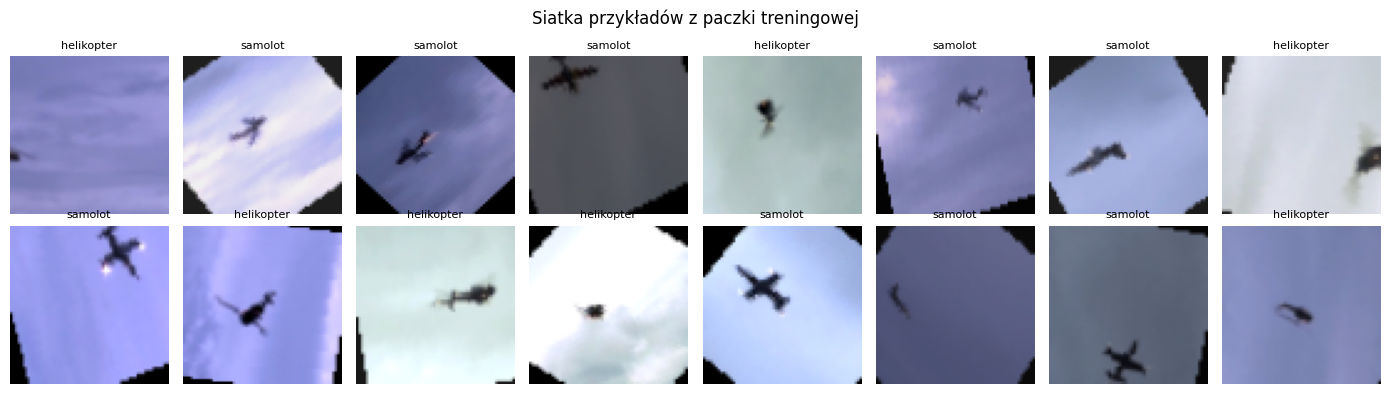

In [8]:
eval_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])
train_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(90),
    transforms.ColorJitter(brightness=0.5, contrast=0.2),
    transforms.RandomResizedCrop(64, scale=(0.6,1.0)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

train_ds = datasets.ImageFolder("moje_dane/train", transform=train_tf)
val_ds = datasets.ImageFolder("moje_dane/val", transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=16, shuffle=False)

print("Statystyki:")
print("Liczba klas:", len(train_ds.classes))
print("Indeksy klas:", train_ds.class_to_idx)
print("Rozmiar zbioru treningowego:", len(train_ds))
print("Rozmiar zbioru walidacyjnego:", len(val_ds))

xb, yb = next(iter(train_dl))
print("Rozmiar paczki po transformacji (N, C, H, W):", tuple(xb.shape))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow((img*0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title(train_ds.classes[lb], fontsize=8); ax.axis("off")
plt.suptitle("Siatka przykładów z paczki treningowej")
plt.tight_layout(); plt.show()

## Podgląd augmentacji

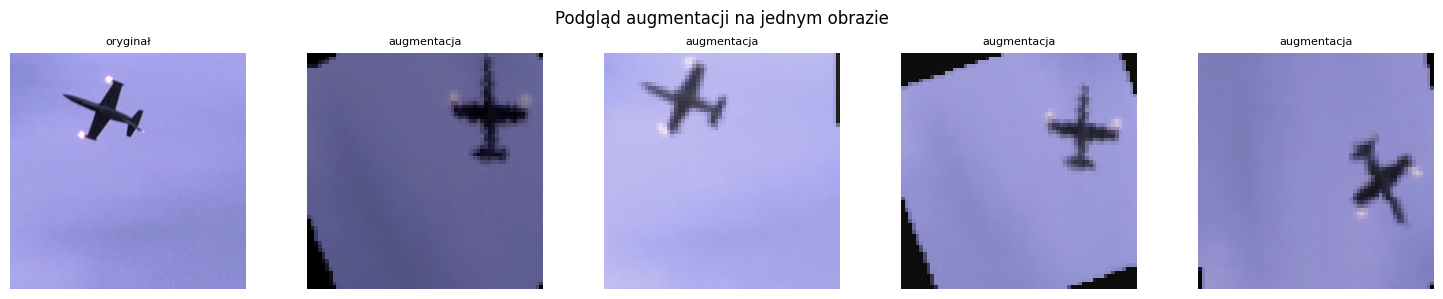

In [9]:
raw_img = Image.open(train_ds.samples[61][0]).convert("RGB")
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(raw_img); axes[0].set_title("oryginał", fontsize=8); axes[0].axis("off")
for ax in axes[1:]:
    aug_img = train_tf(raw_img)
    ax.imshow((aug_img*0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title("augmentacja", fontsize=8); ax.axis("off"); ax.axis("off")
plt.suptitle("Podgląd augmentacji na jednym obrazie")
plt.tight_layout(); plt.show()

## Zakres dodatkowy

In [21]:
import torch.nn as nn
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

model = nn.Sequential(nn.Flatten(), nn.Linear(3 * 64 * 64, 128), nn.ReLU(), nn.Linear(128, 2)).to(device)

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-4)

train_losses, val_losses, val_accuracies = [], [], []
epochs = 10

for epoch in range(epochs):
    model.train()
    total_train_loss = 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_train_loss += loss.item() * len(yb)

    avg_train_loss = total_train_loss / len(train_dl.dataset)
    train_losses.append(avg_train_loss)

    model.eval()
    total_val_loss = 0
    correct = 0
    with torch.no_grad():
        for xb, yb in val_dl:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb)
            loss = loss_fn(preds, yb)
            total_val_loss += loss.item() * len(yb)
            correct += (preds.argmax(1) == yb).sum().item()

    avg_val_loss = total_val_loss / len(val_dl.dataset)
    val_losses.append(avg_val_loss)
    acc = correct / len(val_dl.dataset)
    val_accuracies.append(acc)

    print(f"Epoka {epoch+1}: Train Loss = {avg_train_loss:.3f} | Val Loss = {avg_val_loss:.3f} | Val Acc = {acc:.2f}")

PyTorch: 2.11.0+cpu | urządzenie: cpu
Epoka 1: Train Loss = 0.709 | Val Loss = 0.598 | Val Acc = 0.83
Epoka 2: Train Loss = 0.687 | Val Loss = 0.639 | Val Acc = 0.86
Epoka 3: Train Loss = 0.760 | Val Loss = 0.618 | Val Acc = 0.76
Epoka 4: Train Loss = 0.682 | Val Loss = 0.731 | Val Acc = 0.28
Epoka 5: Train Loss = 0.701 | Val Loss = 0.734 | Val Acc = 0.59
Epoka 6: Train Loss = 0.833 | Val Loss = 0.791 | Val Acc = 0.14
Epoka 7: Train Loss = 0.722 | Val Loss = 0.782 | Val Acc = 0.24
Epoka 8: Train Loss = 0.684 | Val Loss = 0.698 | Val Acc = 0.52
Epoka 9: Train Loss = 0.704 | Val Loss = 0.672 | Val Acc = 0.52
Epoka 10: Train Loss = 0.680 | Val Loss = 0.631 | Val Acc = 0.45


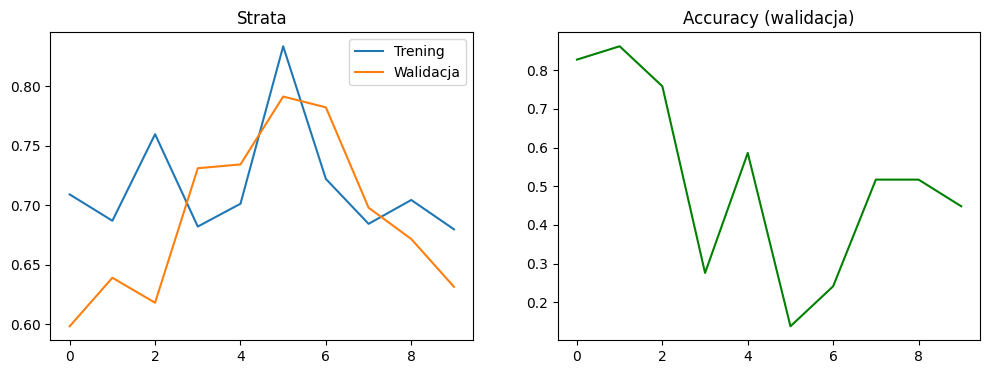

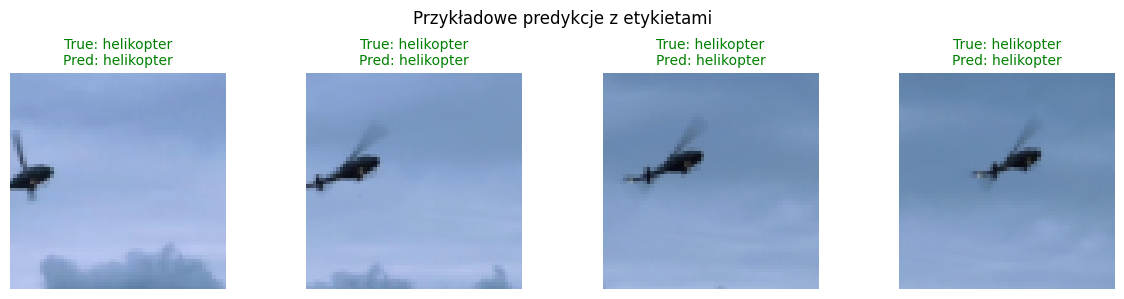

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(train_losses, label='Trening')
ax1.plot(val_losses, label='Walidacja')
ax1.set_title('Strata')
ax1.legend()

ax2.plot(val_accuracies, color='green')
ax2.set_title('Accuracy (walidacja)')
plt.show()

model.eval()
xb_val, yb_val = next(iter(val_dl))
xb_dev = xb_val.to(device)
with torch.no_grad():
    predictions = model(xb_dev).argmax(1).cpu()

fig, axes = plt.subplots(1, min(4, len(xb_val)), figsize=(12, 3))
for i, ax in enumerate(axes):
    img = (xb_val[i] * 0.5 + 0.5).permute(1, 2, 0).numpy()
    true_cls = val_ds.classes[yb_val[i]]
    pred_cls = val_ds.classes[predictions[i]]

    ax.imshow(img)
    color = "green" if true_cls == pred_cls else "red"
    ax.set_title(f"True: {true_cls}\nPred: {pred_cls}", color=color, fontsize=10)
    ax.axis("off")
plt.suptitle("Przykładowe predykcje z etykietami")
plt.tight_layout(); plt.show()

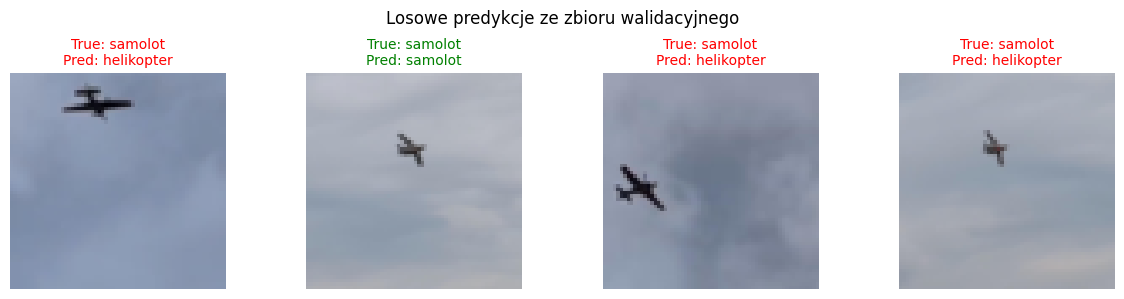

In [35]:
import random

model.eval()
num_samples = min(4, len(val_ds))
random_indices = random.sample(range(len(val_ds)), num_samples)

fig, axes = plt.subplots(1, num_samples, figsize=(12, 3))

for i, idx in enumerate(random_indices):
    img_tensor, true_idx = val_ds[idx]
    img_batch = img_tensor.unsqueeze(0).to(device)
    with torch.no_grad():
        pred_idx = model(img_batch).argmax(1).item()

    img_show = (img_tensor * 0.5 + 0.5).permute(1, 2, 0).numpy()
    true_cls = val_ds.classes[true_idx]
    pred_cls = val_ds.classes[pred_idx]

    axes[i].imshow(img_show)
    color = "green" if true_cls == pred_cls else "red"
    axes[i].set_title(f"True: {true_cls}\nPred: {pred_cls}", color=color, fontsize=10)
    axes[i].axis("off")

plt.suptitle("Losowe predykcje ze zbioru walidacyjnego")
plt.tight_layout()
plt.show()